In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn import metrics

## 6.2 Problem Setting

After a war, dangerous equipment often gets left behind scattered across fields. Over time, these items can become buried in the earth and lost to time. However, at some point later, civilians sometimes discover still-live explosives, leading to dangerous situations. Here in Flanders, for example, farmers still find live mines from WWI when plowing their fields to this day.

To combat this and remove as many dangerous items as possible, governments can take sonar scans of the ground. The dataset we are going to explore today contains a series of objects, each scanned 60 times with sonar from different angles. We are trying to predict whether a scanned object is an actual mine ('M') or a rock shaped like a mine ('R'). These values are stored in the 'Material' column.

**Real-world context**: This is a classic example of where the cost of false negatives (missing an actual mine) is much higher than false positives (incorrectly identifying a rock as a mine).

## 6.3 Model

First, let's examine the structure and characteristics of our sonar data:

In [2]:
df=pd.read_csv("/Users/mohammedsadmanuddin/data science fund/KNN/Sonar.csv")
df.head()


,Sonar1,Sonar2,Sonar3,Sonar4,Sonar5,Sonar6,Sonar7,Sonar8,Sonar9,Sonar10,...,Sonar52,Sonar53,Sonar54,Sonar55,Sonar56,Sonar57,Sonar58,Sonar59,Sonar60,Material
0,0.0664,0.0575,0.0842,0.0372,0.0458,0.0771,0.0771,0.1130,0.2353,0.1838,...,0.0141,0.0190,0.0043,0.0036,0.0026,0.0024,0.0162,0.0109,0.0079,R
1,0.0094,0.0333,0.0306,0.0376,0.1296,0.1795,0.1909,0.1692,0.1870,0.1725,...,0.0153,0.0112,0.0241,0.0164,0.0055,0.0078,0.0055,0.0091,0.0067,M
2,0.0201,0.0178,0.0274,0.0232,0.0724,0.0833,0.1232,0.1298,0.2085,0.2720,...,0.0131,0.0049,0.0104,0.0102,0.0092,0.0083,0.0020,0.0048,0.0036,M
3,0.0526,0.0563,0.1219,0.1206,0.0246,0.1022,0.0539,0.0439,0.2291,0.1632,...,0.0339,0.0149,0.0335,0.0376,0.0174,0.0132,0.0103,0.0364,0.0208,M
4,0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,...,0.0222,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023,M


##### Question 1: Try to plot a heatmap to further explore the data. Do you encounter any errors? Why does this happen? How can you solve this using a method we've already seen in previous chapters?

**Hint**: Think about what type of data correlation matrices can work with and what the 'Material' column contains.

**Encoding**: encode mines ('M') as **1** and rocks ('R') as **0**. A mine is the 'positive' class we want to detect, and scikit-learn treats label 1 as the positive class by default.

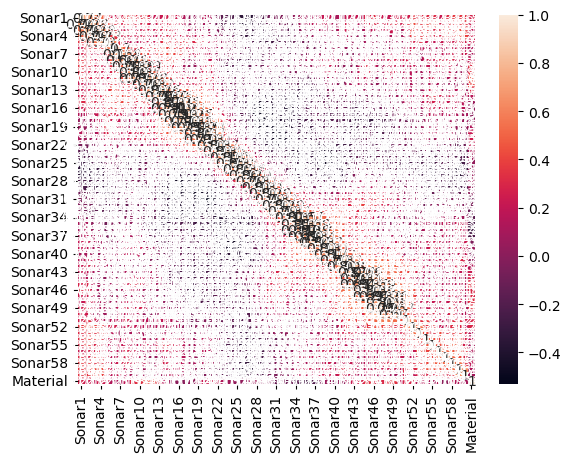

In [3]:
df["Material"] = df["Material"].map({'M':1,"R":0})
sns.heatmap(df.corr(),annot=True,)
plt.show()

**Explain the error you encountered and how to solve it:**

- A correlation heatmap with 60 feature is very large...so we can consider plotting only the corr with materials

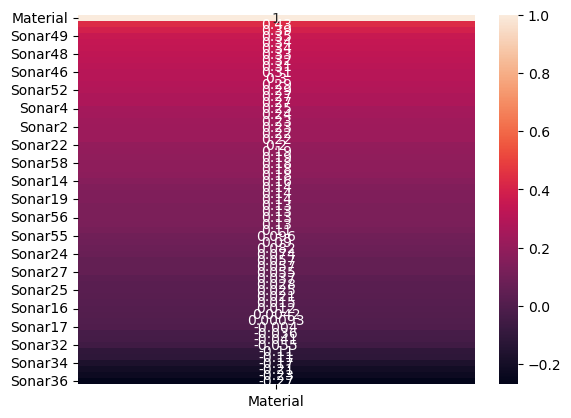

In [4]:
correlations = df.corr()['Material'].sort_values(ascending=False)
sns.heatmap(correlations.to_frame(),annot=True)
plt.show()

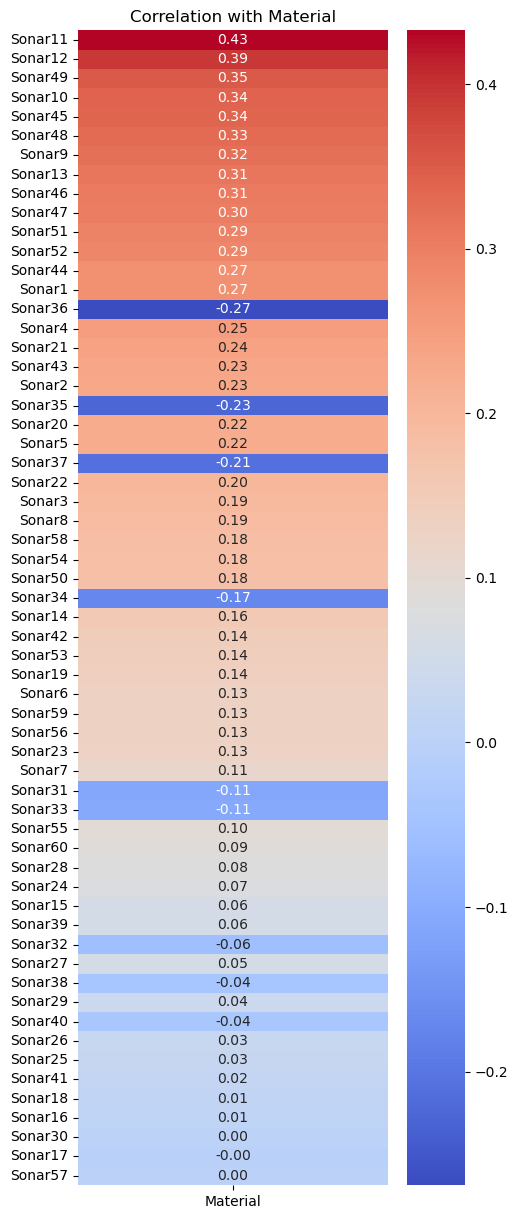

In [5]:
correlations = df.corr()['Material'].drop('Material')
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
plt.figure(figsize=(5, 15))
sns.heatmap(correlations.to_frame(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation with Material')
plt.show()

- The variables with correlation values closest to +1 or -1 have the strongest linear relationships with Material. Variables with correlation values close to zero have the weakest linear relationships.
- Positive correlations indicate that higher sonar readings are associated with mines, while negative correlations indicate that higher readings are associated with rocks.
- example: sonar 38 is -.0.4 and sonar 24 is .0.07...means when sonar 38 reading increase...the possibility of that being a rock increase and mine decrease and when sonar 24 incrase the possibility of that being a mine increase and rock decrease

##### Question 2: Analyze the data by examining the heatmap. Which variables would you expect to have the highest impact on Material prediction, and which ones would you expect to have the lowest impact? Explain your reasoning.

**Analysis tip**: Look at the bottom row of the heatmap (or rightmost column) which shows correlations with the Material variable. Strong positive or negative correlations indicate higher predictive power.

**Your analysis:**

Variables with high correlation to Material:
- variables with high correlation to material is usefull for predicting the material cuz the most positive and negetive correlation to materials indicates to mine and rock

Variables with low correlation to Material:
- variables with low mean which is closer to 0 or exact 0 have small or weak linear relationship with material

##### Question 3: Build and train your k-NN model. Make sure to:
- Keep some data aside for testing (use train-test split)
- Exclude the target column ('Material') from your training features
- Choose an appropriate test size and random state for reproducibility

**Reminder**: The features (X) should contain all sonar measurements, while the target (y) should contain only the Material labels.

In [6]:
X = df.drop(["Material"],axis=1)
y=df['Material']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.7,random_state=42)

In [7]:
model = KNeighborsClassifier() # defualt k for now
model.fit(X_train,y_train)

KNeighborsClassifier()

##### Question 4: Predict the materials for your test data. Analyze the distribution of predictions:
- How many rocks are predicted in the test set?
- How many mines are predicted in the test set?
- Does this distribution seem reasonable given the problem context?

**Analysis tip**: `predict()` returns a NumPy array, so convert it first: `pd.Series(predictions).value_counts()` gives a quick summary of the distribution.

In [8]:
predictions = model.predict(X_test)
a = (predictions == 1).sum() #mine
b = (predictions == 0).sum() #rock
# for i in model.predict(X_test):
#     if i == 1:
#         a += 1
#     else:
#         b += 1
print(f"rocks {b} and mines {a}")

rocks 73 and mines 73


**Your analysis:**

- Number of rocks predicted: 73
- Number of mines predicted: 73
- Analysis of distribution: the knn model predicted equal amount of rock and mines...this looks reasonable as both classes are represented equally in the predictions...but the best way to check it is to evaluate models and check confusion matrix

## 6.4 Model Evaluation

Of course, our predictions don't mean anything without knowing how accurate they are. Let's evaluate our model's performance using various metrics:

##### Question 5: Evaluate your model's performance by calculating accuracy and precision. Is your model performing well? Provide a detailed analysis of what these metrics tell you about your model's effectiveness.

**Key definitions**:
- **Accuracy**: Overall percentage of correct predictions
- **Precision**: Of all positive predictions (mines), how many were actually correct?

**Note**: `precision_score` uses label 1 as the positive class. This only measures precision for mines if you encoded mines as 1 in Question 1.

In [9]:
print("accuracy:",accuracy_score(y_test,predictions))
print("precision:",precision_score(y_test,predictions,average="weighted"))

accuracy: 0.678082191780822
precision: 0.6856821167198348


**Your analysis:**

Accuracy: the model correctly predicts 67% of all object right...

Precision: the model predicted 68% as mines

Overall performance assessment: its not a strong model after all...it only predicted 67% right and moreover it predicted 68% as mines which is two third of test set

##### Question 6: Create and analyze a confusion matrix to visually confirm your previous findings. What patterns do you observe? How does this matrix support or contradict your accuracy and precision calculations?

**Confusion matrix reminder**: 
- Diagonal elements = correct predictions
- Off-diagonal elements = incorrect predictions
- For binary classification with mine = 1: [[TN, FP], [FN, TP]] (rows = actual, columns = predicted)

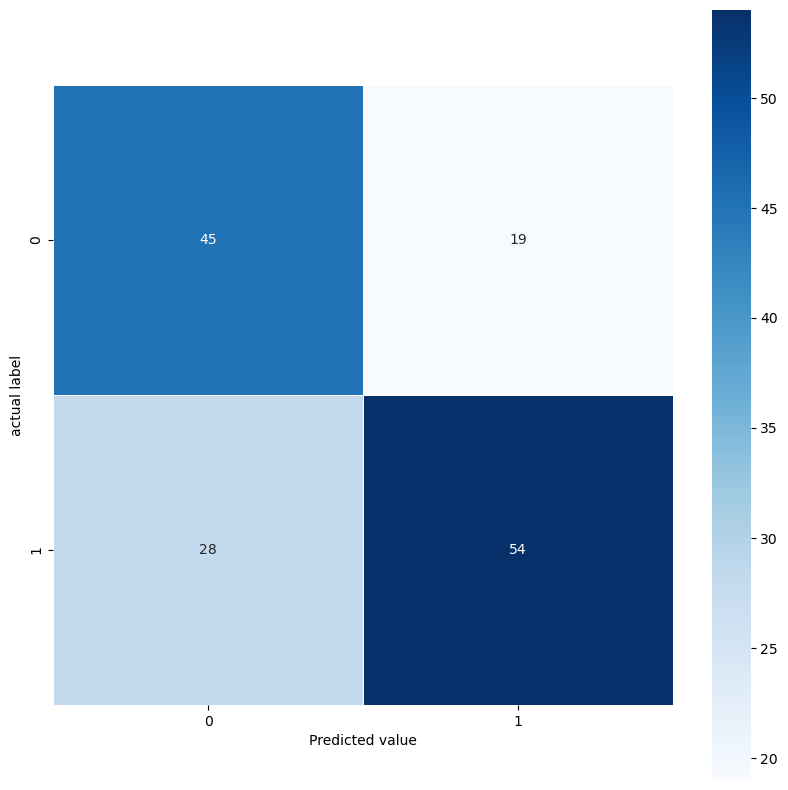

In [10]:
cm = metrics.confusion_matrix(y_test,predictions)
plt.figure(figsize=(10,10))
sns.heatmap(cm,annot=True,fmt="d",linewidths=.5,square=True,cmap='Blues')
plt.ylabel("actual label")
plt.xlabel('Predicted value')
plt.show()

**MY analysis of the confusion matrix:**

Patterns observed: 
- the model correctly identifies 45(TN) rock and incorrectly classified 19(FP) rocks as mines
- the model correctly identifies 54(TP) miens and incorrectly classified 28(FN) mines as rock

##### Question 7: Calculate the additional evaluation metrics we've studied (recall, specificity, F1-score). Analyze each metric - are they satisfactory? In this specific mine detection dataset, would you prefer high recall or high specificity? Justify your choice with the real-world implications.

*Remember: We're working with a binary classification problem, not multiclass!*

**Critical thinking**: Consider the consequences of false positives vs. false negatives in a mine detection scenario.

In [11]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.62      0.70      0.66        64
           1       0.74      0.66      0.70        82

    accuracy                           0.68       146
   macro avg       0.68      0.68      0.68       146
weighted avg       0.69      0.68      0.68       146



## 6.5 Questions

##### Question 8: By default, scikit-learn uses k=5 as the number of nearest neighbors. Find the optimal value by plotting accuracy across a range of possible k values. What patterns do you observe?

**Hyperparameter tuning**: This process of finding the best parameter values is crucial for model optimization.

**Tip**: With two classes, an even k can lead to a tied vote. Consider using only odd values of k.

best_k: 3 with accuracy 0.726027397260274


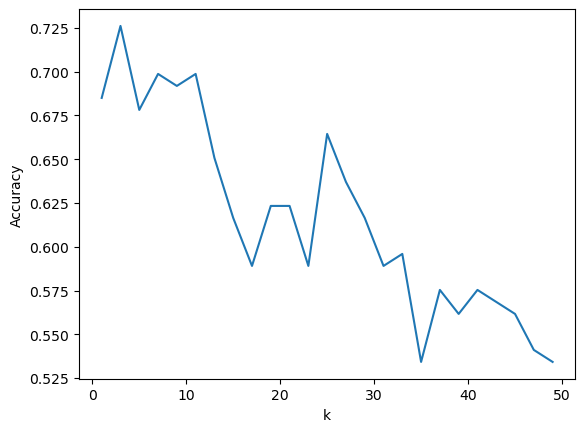

In [12]:
k_values = range(1,50,2)
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    accuracies.append(accuracy_score(y_test,model.predict(X_test)))
best_k = k_values[np.argmax(accuracies)]
print("best_k:",best_k,"with accuracy",max(accuracies))
plt.plot(k_values,accuracies)
plt.xlabel('k')
plt.ylabel("Accuracy")
plt.show()

**Your observations:**

Optimal k value: 3

Patterns observed: we can see accuracy decrease when k increases...cuz small k means less neighbors...so at 3 as k the best accuracy we found which is 72%

##### Question 9: Repeat the analysis for the metric you want to maximize (recall, based on your previous analysis). Does your preferred value for k change? Which k value would be 'best' overall for this dataset?

**Strategy**: Since recall is most important for mine detection, we should optimize for recall rather than just accuracy.

best_k: 9 with recall 0.7317073170731707


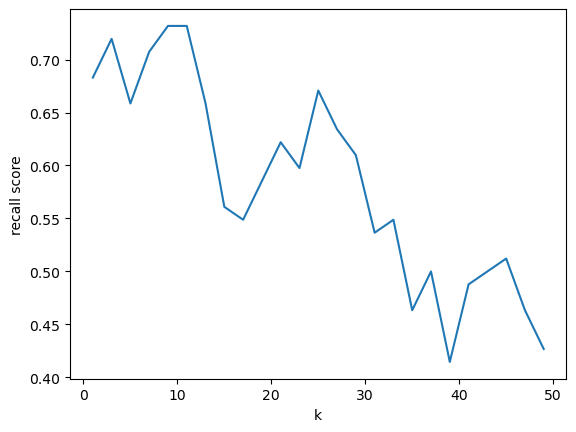

In [13]:
k_values = range(1,50,2)
recalls = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    recalls.append(recall_score(y_test,model.predict(X_test)))
best_k = k_values[np.argmax(recalls)]
print("best_k:",best_k,"with recall",max(recalls))
plt.plot(k_values,recalls)
plt.xlabel('k')
plt.ylabel("recall score")
plt.show()

**Your analysis:**

Optimal k for recall: 9

Does k change when optimizing for recall vs accuracy? - Yes. Accuracy measures overall correctness, whereas recall measures how many actual mines the model successfully detects.

Best overall k value: 9 cuz we need good recall score cuz a wrong prediction of mine can be dangerous.

##### Question 10: Train logistic regression, decision tree, and random forest models on this same data. Optimize each model using techniques from previous lessons to find the best possible performance. Compare all models - which do you prefer overall?

**Comparative analysis**: This will help you understand which algorithm works best for this specific problem and dataset characteristics.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

Accuracy: 0.6986301369863014
Precision: 0.796875
Recall: 0.6219512195121951


<Axes: >

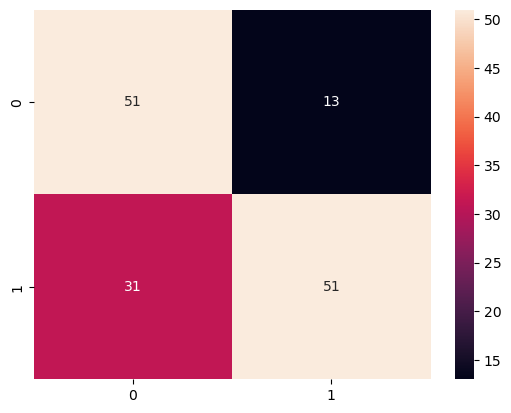

In [15]:
Logistic = LogisticRegression()
Logistic.fit(X_train,y_train)
print("Accuracy:", accuracy_score(y_test,Logistic.predict(X_test)))
print("Precision:", precision_score(y_test, Logistic.predict(X_test)))
print("Recall:", recall_score(y_test, Logistic.predict(X_test)))
sns.heatmap(metrics.confusion_matrix(y_test, Logistic.predict(X_test)),annot=True)

Accuracy: 0.6575342465753424
Precision: 0.6904761904761905
Recall: 0.7073170731707317


<Axes: >

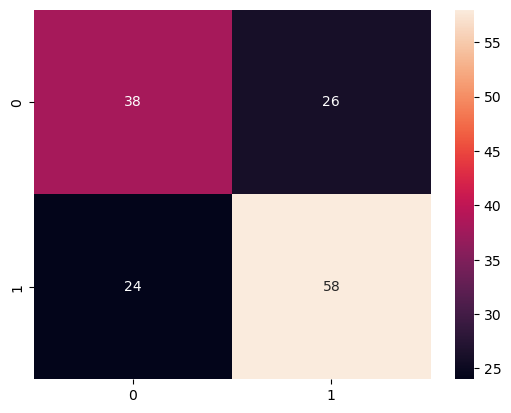

In [16]:
tree = DecisionTreeClassifier()
tree.fit(X_train,y_train)
print("Accuracy:", accuracy_score(y_test,tree.predict(X_test)))
print("Precision:", precision_score(y_test, tree.predict(X_test)))
print("Recall:", recall_score(y_test, tree.predict(X_test)))
sns.heatmap(metrics.confusion_matrix(y_test, tree.predict(X_test)),annot=True)

Accuracy: 0.7602739726027398
Precision: 0.8615384615384616
Recall: 0.6829268292682927


<Axes: >

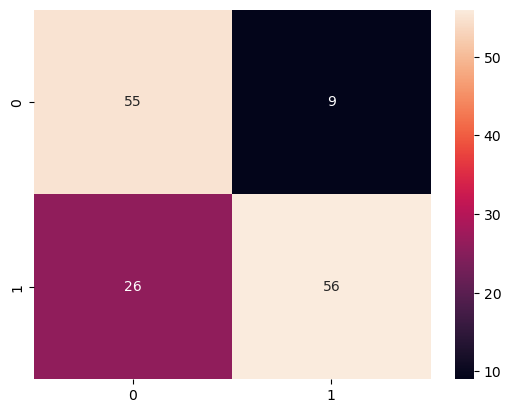

In [17]:
Random = RandomForestClassifier()
Random.fit(X_train,y_train)
print("Accuracy:", accuracy_score(y_test,Random.predict(X_test)))
print("Precision:", precision_score(y_test, Random.predict(X_test)))
print("Recall:", recall_score(y_test, Random.predict(X_test)))
sns.heatmap(metrics.confusion_matrix(y_test, Random.predict(X_test)),annot=True)

**Your model comparison:**

Best performing model: random forest...accuracy score highest

Justification: random forest...cuz the recall score matters the most in this dataset and random forest has the highest recall score